# GUESSER quickstart

GUESSER predicts the stability change (ΔΔG, kcal mol⁻¹; positive = destabilizing) of single and double mutations, an uncertainty for each prediction, and an explanation of both. This notebook walks through the three outputs with the eight released ensemble members:

1. **Predict** ΔΔG with its epistemic uncertainty σ_e
2. **Use the uncertainty**: calibrated intervals and the probability that a mutation is neutral or stabilizing
3. **Explain** a prediction and its uncertainty with integrated gradients
4. **Run it on your own structure**

Sections 1–3 use 41 graph pairs bundled in `examples/` (SSYM single mutants and PTMUL-D double mutants) and run on a CPU in about a minute. Section 4 builds graphs from a PDB file and needs MadraX.

In [1]:
import os, sys
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from scipy.stats import norm

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
from guesser.inference import predict, released_weights, metrics, S_STAR
from guesser.features import FEATURE_NAMES

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
SINGLE, DOUBLE = "#2B5C8F", "#7B4397"
ONE = dict(ALA="A", ARG="R", ASN="N", ASP="D", CYS="C", GLN="Q", GLU="E", GLY="G", HIS="H", ILE="I",
           LEU="L", LYS="K", MET="M", PHE="F", PRO="P", SER="S", THR="T", TRP="W", TYR="Y", VAL="V")
def short(mutation):
    """[('A', 'GLU', 46, 'ALA'), ...] -> 'E46A/...'"""
    return "/".join(f"{ONE[w]}{p}{ONE[m]}" for _, w, p, m in eval(mutation))

weights = released_weights(os.path.join(ROOT, "weights"))
print(f"{len(weights)} ensemble members; validation scale factor s* = {S_STAR:.2f}")

8 ensemble members; validation scale factor s* = 1.71


## 1. Predict ΔΔG and its uncertainty

`predict` runs every member on every graph pair and combines them as in the paper:

| column | meaning |
| --- | --- |
| `pred_ddg` | μ, the mean of the members' predictions; μ = γ_base + γ_epi + γ_phys |
| `intra_epistemic_std` | σ_e = √(mean β/(ν(α−1))), the epistemic uncertainty |
| `calibrated_std` | s*·σ_e, calibrated on the MegaScale validation set (s* = 1.71) |
| `aleatoric_std` | σ_a = √(mean β/(α−1)) |
| `inv_phi` | 1/Φ = mean 1/(2ν+α), the inverse total evidence (unitless, for ranking) |

In [2]:
graphs = torch.load(os.path.join(ROOT, "examples", "example_graphs.pt"), weights_only=False)
ens = predict(graphs, weights, device="cpu")
ens["type"] = np.where(ens.num_muts > 1, "double", "single")
cols = ["pdb", "mutation", "type", "true_ddg", "pred_ddg", "intra_epistemic_std", "calibrated_std", "aleatoric_std", "inv_phi"]
ens[cols].round(3).head(8)

,pdb,mutation,type,true_ddg,pred_ddg,intra_epistemic_std,calibrated_std,aleatoric_std,inv_phi
0,1amq.pdb,"[('A', 'CYS', 191, 'TYR')]",single,2.30,1.299,0.354,0.605,0.014,0.458
1,1l63.pdb,"[('A', 'ALA', 73, 'SER')]",single,0.40,0.032,0.210,0.359,0.024,0.341
2,1lz1.pdb,"[('A', 'ILE', 59, 'VAL')]",single,1.10,1.002,0.580,0.991,0.024,0.462
3,2lzm.pdb,"[('A', 'VAL', 149, 'CYS')]",single,2.20,1.025,0.737,1.260,0.036,0.506
4,1ey0.pdb,"[('A', 'PRO', 117, 'ALA')]",single,-0.80,1.145,0.674,1.152,0.031,0.502
5,1l63.pdb,"[('A', 'VAL', 111, 'ILE')]",single,0.90,-0.271,0.729,1.245,0.033,0.475
6,1rn1.pdb,"[('C', 'GLN', 25, 'LYS')]",single,-0.93,-0.470,0.243,0.415,0.022,0.351
7,4lyz.pdb,"[('A', 'GLY', 67, 'ALA')]",single,0.50,0.619,0.250,0.427,0.013,0.379


The prediction is a sum of three parts: the structural (global) head γ_base, the multi-mutation head γ_epi, which is exactly zero for single mutants, and the linear physics prior γ_phys on the summed MadraX energy differences.

{'N': 41, 'PCC': 0.531, 'Spearman': 0.529, 'RMSE': 1.029, 'MAE': 0.713}


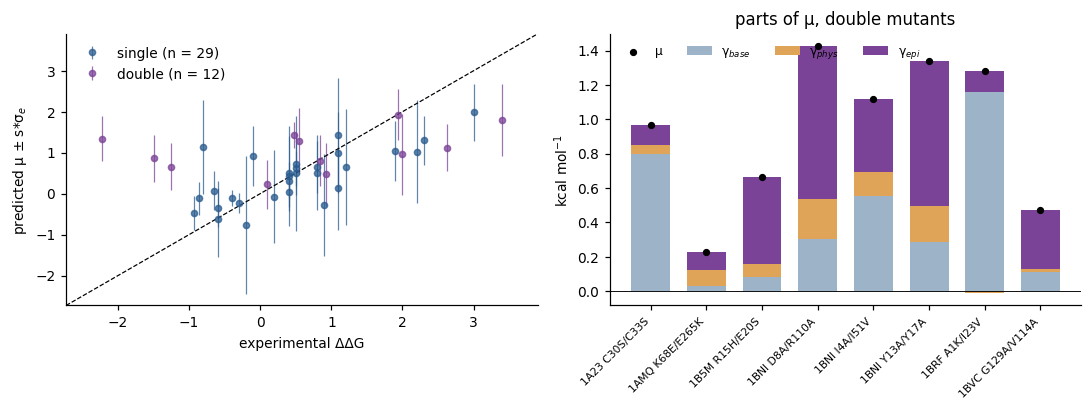

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for t, c in (("single", SINGLE), ("double", DOUBLE)):
    s = ens[ens.type == t]
    ax[0].errorbar(s.true_ddg, s.pred_ddg, yerr=s.calibrated_std, fmt="o", ms=4, color=c, alpha=.75,
                   elinewidth=.8, capsize=0, label=f"{t} (n = {len(s)})")
lim = [min(ens.true_ddg.min(), ens.pred_ddg.min()) - .5, max(ens.true_ddg.max(), ens.pred_ddg.max()) + .5]
ax[0].plot(lim, lim, "k--", lw=.8); ax[0].set(xlim=lim, ylim=lim, xlabel="experimental ΔΔG", ylabel="predicted μ ± s*σ$_e$")
ax[0].legend(frameon=False)

d = ens[ens.type == "double"].head(8).reset_index(drop=True)
x = np.arange(len(d)); bottom = np.zeros(len(d))
for part, c, lab in (("pred_base", "#9DB4C8", "γ$_{base}$"), ("pred_phys", "#E0A458", "γ$_{phys}$"), ("pred_epi", DOUBLE, "γ$_{epi}$")):
    v = d[part].values
    ax[1].bar(x, v, bottom=np.where(v > 0, np.maximum(bottom, 0), np.minimum(bottom, 0)), color=c, label=lab, width=.7)
    bottom += v
ax[1].scatter(x, d.pred_ddg, color="k", zorder=3, s=14, label="μ")
labels = [f"{p.replace('.pdb', '')} {short(m)}" for p, m in zip(d.pdb, d.mutation)]
ax[1].axhline(0, color="k", lw=.6); ax[1].set(xticks=x, xticklabels=labels,
                                              ylabel="kcal mol$^{-1}$", title="parts of μ, double mutants")
ax[1].tick_params(axis="x", rotation=45, labelsize=7)
plt.setp(ax[1].get_xticklabels(), ha="right"); ax[1].legend(frameon=False, ncol=4, fontsize=8)
plt.tight_layout()
print({k: round(v, 3) for k, v in metrics(ens).items()})

## 2. Use the uncertainty

The calibrated predictive distribution of a mutation is N(μ, (s*σ_e)²). From it we get an interval for each prediction and the probability of an outcome. In the paper, ranking by such probabilities, rather than by μ alone, gave fewer wrong picks among variants predicted to be neutral or stabilizing (Fig. 6).

In [4]:
sd = ens.calibrated_std
ens["P_neutral"] = norm.cdf((0.5 - ens.pred_ddg) / sd) - norm.cdf((-0.5 - ens.pred_ddg) / sd)   # |ΔΔG| < 0.5
ens["P_stabilizing"] = norm.cdf(-ens.pred_ddg / sd)                                              # ΔΔG < 0
ens["low_95"], ens["high_95"] = ens.pred_ddg - 1.96 * sd, ens.pred_ddg + 1.96 * sd

print("Most likely stabilizing:")
display(ens.sort_values("P_stabilizing", ascending=False)[["pdb", "mutation", "pred_ddg", "calibrated_std", "P_stabilizing", "true_ddg"]].head(5).round(2))
print("Most likely neutral:")
display(ens.sort_values("P_neutral", ascending=False)[["pdb", "mutation", "pred_ddg", "calibrated_std", "P_neutral", "true_ddg"]].head(5).round(2))

Most likely stabilizing:


,pdb,mutation,pred_ddg,calibrated_std,P_stabilizing,true_ddg
6,1rn1.pdb,"[('C', 'GLN', 25, 'LYS')]",-0.47,0.42,0.87,-0.93
15,1l63.pdb,"[('A', 'SER', 44, 'ALA')]",-0.22,0.25,0.81,-0.30
24,2lzm.pdb,"[('A', 'SER', 38, 'ASP')]",-0.34,0.47,0.76,-0.60
14,2rn2.pdb,"[('A', 'VAL', 74, 'ILE')]",-0.61,0.92,0.75,-0.60
10,2lzm.pdb,"[('A', 'GLN', 123, 'GLU')]",-0.10,0.19,0.71,-0.40


Most likely neutral:


,pdb,mutation,pred_ddg,calibrated_std,P_neutral,true_ddg
10,2lzm.pdb,"[('A', 'GLN', 123, 'GLU')]",-0.10,0.19,0.98,-0.40
15,1l63.pdb,"[('A', 'SER', 44, 'ALA')]",-0.22,0.25,0.87,-0.30
1,1l63.pdb,"[('A', 'ALA', 73, 'SER')]",0.03,0.36,0.83,0.40
13,1lz1.pdb,"[('A', 'VAL', 110, 'ILE')]",-0.11,0.40,0.77,-0.86
27,1lz1.pdb,"[('A', 'VAL', 74, 'MET')]",0.07,0.47,0.70,-0.65


## 3. Explain a prediction

Integrated gradients attribute an output to the 23 node features of every residue in the graph. The **mutation attribution** integrates the feature changes caused by the mutation, starting from a null mutation (no change) with the wild-type environment held fixed. Its attributions add up to μ − μ_null, where μ_null is the prediction for a mutation that changes nothing.

The same is done for the uncertainty, on log σ_e. This splits it into the **site baseline** g₀ (the uncertainty of a null mutation at the same site) and the **mutation-specific part** g − g₀.

Attributions are computed for each member and averaged. Since IG is linear, the average for μ is exactly the attribution of the ensemble prediction.

In [5]:
from torch_geometric.data import Batch
from guesser.explain.core import explain_batch, load_explain_model

# a double mutant: E46A/L66E in 1C9O (PTMUL-D)
i = next(k for k, it in enumerate(graphs) if it["pdb"] == "1C9O.pdb" and short(it["mutation"]) == "E46A/L66E")
g_wt, g_mt = graphs[i]["graph_pair"]
bw, bm = Batch.from_data_list([g_wt]), Batch.from_data_list([g_mt])
runs = []
for w in weights:
    model = load_explain_model(w, 23, torch.device("cpu"), torch.float64)
    runs.append(explain_batch(model, bw, bm, n_steps=32, fast=True, max_nodes_per_pass=5000)[0][0])
mean = lambda key: np.mean([r[key] for r in runs], axis=0)
A_mu, A_sig = mean("signed_attr_mu"), mean("signed_attr_epistemic")       # [nodes, 23]
g, g0 = mean("f_mut_epistemic"), mean("f0_mut_epistemic")

print(graphs[i]["pdb"].replace(".pdb", ""), short(graphs[i]["mutation"]), f"(experimental ΔΔG {ens.true_ddg[i]:.2f})")
print(f"μ = {mean('f_mut_mu'):.2f} = μ_null {mean('f0_mut_mu'):.2f} + attributions {A_mu.sum():.2f} kcal/mol")
print(f"log σ_e = {g:.2f} = site baseline g0 {g0:.2f} + mutation-specific {A_sig.sum():.2f}")

1C9O E46A/L66E (experimental ΔΔG 0.84)
μ = 0.80 = μ_null 0.05 + attributions 0.75 kcal/mol
log σ_e = -1.12 = site baseline g0 -0.71 + mutation-specific -0.42


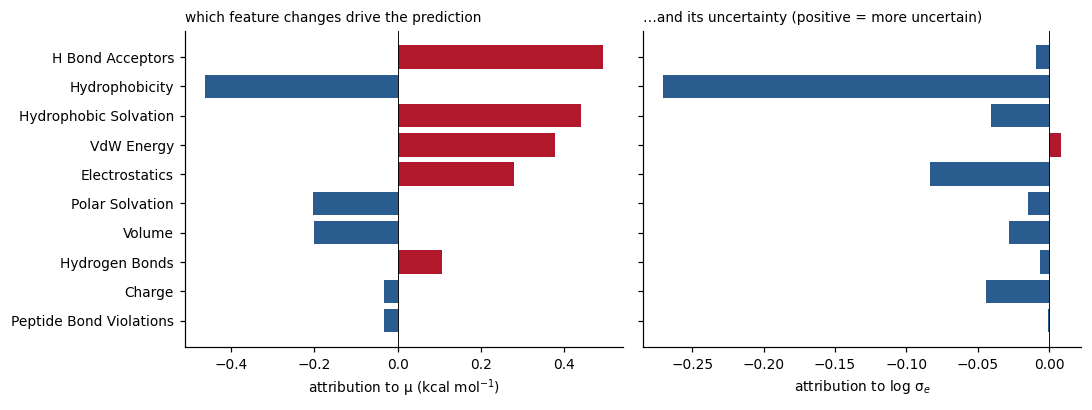

In [6]:
names = [f.replace("_", " ") for f in FEATURE_NAMES]
feat_mu = pd.Series(A_mu.sum(0), index=names)
feat_sig = pd.Series(A_sig.sum(0), index=names)
top = feat_mu.abs().nlargest(10).index[::-1]     # the ten features with the largest attribution to μ

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for a, s, lab in ((ax[0], feat_mu, "attribution to μ (kcal mol$^{-1}$)"), (ax[1], feat_sig, "attribution to log σ$_e$")):
    a.barh(top, s[top], color=np.where(s[top] > 0, "#B2182B", "#2B5C8F"))
    a.axvline(0, color="k", lw=.6); a.set_xlabel(lab)
ax[0].set_title("which feature changes drive the prediction", loc="left", fontsize=9)
ax[1].set_title("…and its uncertainty (positive = more uncertain)", loc="left", fontsize=9)
plt.tight_layout()

Summing over features instead gives a per-residue attribution that can be mapped onto the structure. Only residues whose features change receive a mutation attribution: the mutated residues and the neighbours whose MadraX terms change.

In [7]:
res = pd.DataFrame({"node": np.arange(A_mu.shape[0]), "mutated": g_wt.mut_mask.numpy(),
                    "attribution_mu": A_mu.sum(1), "attribution_log_sigma_e": A_sig.sum(1)})
res.reindex(res.attribution_mu.abs().sort_values(ascending=False).index).head(8).round(3)

,node,mutated,attribution_mu,attribution_log_sigma_e
13,13,True,1.463,-0.388
20,20,True,-0.754,0.005
3,3,False,0.098,-0.057
1,1,False,-0.055,0.054
19,19,False,-0.043,-0.007
14,14,False,0.021,-0.003
15,15,False,0.009,-0.007
2,2,False,0.009,-0.002


For the paper's benchmark sets, the full explanations (per residue, per feature, mutation and environment attributions, with residue labels) are released as HDF5 files. Read them with `guesser.explain.h5.ExplanationFile`: `ef.summary()`, `ef.mutation(i)`, `ef.node_array("signed_attr_mu", i)`.

## 4. Your own structure

Give a PDB file and mutations as `A:L45F`, `L45F` (chain taken from `default_chain`) or `A:L45F+A:G50A` for a double mutant. Graph construction runs MadraX on the structure; install our faster fork first (Linux x86-64, Python 3.7–3.12):

```bash
pip install "git+https://github.com/davsjob/madrax.git"
```

In [8]:
from guesser.structure import MADRAX_AVAILABLE
from guesser.graphs import build_graphs, mutation_table, check_graphs

PDB_FILE = os.path.join(ROOT, "examples", "my_protein.pdb")   # <- your structure
MUTATIONS = ["A:L45F", "A:G50A", "A:L45F+A:G50A"]               # <- your mutations

if MADRAX_AVAILABLE and os.path.exists(PDB_FILE):
    table = mutation_table(os.path.basename(PDB_FILE), MUTATIONS, default_chain="A")
    my_graphs = build_graphs(table, os.path.dirname(PDB_FILE), radii=[9.0], edge_cutoff=9.0)[9.0]
    check_graphs(my_graphs)
    display(predict(my_graphs, weights)[["mutation", "pred_ddg", "calibrated_std", "inv_phi"]].round(3))
else:
    print("Set PDB_FILE to a structure and install MadraX to run this cell.")

Set PDB_FILE to a structure and install MadraX to run this cell.


The same from the command line:

```bash
guesser predict --pdb my_protein.pdb --mutations A:L45F A:G50A A:L45F+A:G50A --out preds.csv
```